# THINGS-EEG2: validation split + preprocessing (within-subject and leave-one-subject-out)

This notebook fixes the **order of operations** so that nothing from validation or test leaks into preprocessing:

1. Fix the validation split (a fixed list of validation **concepts**, ~10%) and the LOSO folds (1 test subject, **2 validation subjects**, the rest train).
2. Fit the preprocessing parameters **only on training trials** (training concepts only, never validation concepts, never the test EEG).
3. Apply the same fixed function to train, validation and test.

**What is individual and what is shared**

| Item | Choice | Why |
|---|---|---|
| Centre and scale per channel (robust: median and 1.4826*MAD) | **individual**, one set per subject | subjects differ a lot in amplitude and outlier rate |
| Clip threshold, in robust-sd units | **shared**, chosen from training data of all subjects | a design decision, same for everyone; in robust units it acts individually |
| Channels, time window (0-590 ms), averaging of repetitions | **shared** | design decisions |

**Data leakage rules used here**
- Everything is computed from training trials of training concepts. Test EEG is only *transformed* with parameters fitted on train, and no test metric is computed.
- Tags: **[TRAIN]** derived from training data only (safe for decisions), **[PROXY]** a quick check, final decision must come from the trained model's validation score.

**LOSO design used here:** for test subject *s*, the 2 validation subjects are the next two subjects in cyclic order, the other 7 are training subjects. Training subjects use only **training concepts**. Validation = validation subjects x **validation concepts**. Test = subject *s* on the 200 test images, only at the very end.

**Colab:** add the Secret `HF_TOKEN` (read access) and set `REPO_ID` below (or the env var `HF_REPO_ID`). A CPU runtime is enough (about 3 GB RAM peak with `SOURCE = '17ch'`; use High-RAM for `63ch_p17`).

In [3]:
import os, sys, json, time, gc, pickle, subprocess, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ------------------------------ config ------------------------------
REPO_ID = os.environ.get('HF_REPO_ID', 'things-eeg2/things-eeg2-preprocessed')   # <- put the real org/repo here
LOCAL_ROOT = os.environ.get('EDA_LOCAL_ROOT')                   # None on Colab -> download from the Hub
WORK = os.environ.get('EDA_WORK', '/content/work')
SOURCE = os.environ.get('EDA_SOURCE', '17ch')                   # '17ch' = the 17-channel files, '63ch_p17' = the same 17 channels cut from the 63-channel files
SUBJECTS = os.environ.get('EDA_SUBJECTS', ','.join(f'sub-{i:02d}' for i in range(1, 11))).split(',')
SEED = 0
VAL_FRAC = 0.10                  # share of training concepts used for validation
N_VAL_SUBJECTS = 2               # validation subjects per LOSO fold
CROP_MS = (0, 590)               # model input window
CLIP_K_OVERRIDE = None           # None -> chosen from training data in section 3
K_GRID = [3, 4, 5, 6, 8, 10, 15, 20]
CLIP_RULE = 1e-3                 # choose the smallest K that clips <= 0.1% of training points
N_STAT_IMAGES = 3000             # training images (training concepts) used to fit the statistics
N_TRAIN_SUB = 1500               # of those, how many are kept for the window sweep
N_DRAWS = 20
OUT = os.path.join(WORK, 'out'); os.makedirs(OUT, exist_ok=True)
TS = np.arange(100) * 0.01 - 0.2                                # -0.20 ... 0.79 s
CROP = (TS >= CROP_MS[0] / 1000 - 1e-9) & (TS <= CROP_MS[1] / 1000 + 1e-9)
t0 = time.time()
def log(*a): print(f'[{time.time()-t0:6.0f}s]', *a, flush=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(OUT, name), dpi=110); plt.show()
assert SOURCE in ('17ch', '63ch_p17')
assert len(SUBJECTS) >= N_VAL_SUBJECTS + 2, 'need at least 1 test + 2 validation + 1 training subject'

# ------------------------------ Hugging Face access ------------------------------
if not LOCAL_ROOT:
    assert 'PUT_ORG_NAME' not in REPO_ID, 'set REPO_ID (org/repo) in the config cell'
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'huggingface_hub'], check=False)
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get('hf_token')
    except Exception:
        HF_TOKEN = os.environ.get('hf_token')
    if not HF_TOKEN:
        from getpass import getpass
        HF_TOKEN = getpass('Hugging Face token (read access): ')
    from huggingface_hub import hf_hub_download

def get_file(rel):
    if LOCAL_ROOT:
        return os.path.join(LOCAL_ROOT, rel)
    return hf_hub_download(REPO_ID, rel, repo_type='dataset', token=HF_TOKEN, local_dir=WORK)

def release(path):
    if not LOCAL_ROOT and os.path.exists(path):
        os.remove(path)

# restricted unpickler: the .npy files are pickled dicts, only NumPy types are allowed
_OK = {('numpy', 'ndarray'), ('numpy', 'dtype'),
       ('numpy.core.multiarray', '_reconstruct'), ('numpy._core.multiarray', '_reconstruct'),
       ('numpy.core.multiarray', 'scalar'), ('numpy._core.multiarray', 'scalar'),
       ('builtins', 'dict'), ('builtins', 'list')}
class _U(pickle.Unpickler):
    def find_class(self, module, name):
        if (module, name) in _OK:
            return getattr(__import__(module, fromlist=[name]), name)
        raise pickle.UnpicklingError(f'blocked {module}.{name}')
def safe_load(path):
    obj = np.load(path, allow_pickle=True)
    return obj.item() if isinstance(obj, np.ndarray) and obj.shape == () else obj

# ------------------------------ identification metric (arrays already windowed) ------------------------------
def _norm_rows(F):
    F = F - F.mean(1, keepdims=True)
    return F / (np.linalg.norm(F, axis=1, keepdims=True) + 1e-12)

def ident_arr(Q, G):
    """Q, G: (n, ch, t); row i of Q and row i of G are the same image. Retrieve each Q among all G. Returns top1, top5."""
    Q = (Q - Q.mean(0)).reshape(len(Q), -1); G = (G - G.mean(0)).reshape(len(G), -1)
    C = _norm_rows(Q) @ _norm_rows(G).T
    o = np.argsort(-C, 1)[:, :5]; gt = np.arange(len(Q))[:, None]
    return float((o[:, :1] == gt).mean()), float((o == gt).any(1).mean())

# channel names of the 17-channel set
CH17 = safe_load(get_file(f'eeg/17ch/{SUBJECTS[0]}/preprocessed_eeg_test.npy'))['ch_names']
def load_eeg(s, split):
    """Returns (array (n_img, reps, 17, 100), channel names). Drops `stim` automatically in 63ch_p17 mode."""
    if SOURCE == '17ch':
        p = get_file(f'eeg/17ch/{s}/preprocessed_eeg_{split}.npy'); T = safe_load(p); release(p)
        X = T['preprocessed_eeg_data']; assert T['ch_names'] == CH17
    else:
        p = get_file(f'eeg/63ch/{s}/preprocessed_eeg_{split}.npy'); T = safe_load(p); release(p)
        idx = [T['ch_names'].index(c) for c in CH17]
        X = T['preprocessed_eeg_data'][:, :, idx]
    assert X.shape[2:] == (17, 100), X.shape
    return X
log('setup ok | source =', SOURCE, '| subjects =', len(SUBJECTS), '| window points =', int(CROP.sum()))

[     2s] setup ok | source = 17ch | subjects = 10 | window points = 60


## 1. Fixed validation split and LOSO folds
- **Validation concepts:** a random 10% of the 1,654 training concepts (all 10 images of each), fixed by `SEED`, saved to `split_concepts.json`. The same list is used for every subject, model and fold.
- **Why by concept:** the 10 images of a concept are alike, and the test set is concept-disjoint (zero-shot), so validation must be concept-disjoint as well (section 5 of the EDA). The split does not look at any EEG.
- **Within-subject (subject *s*):** train = training concepts of *s*, validation = validation concepts of *s*, test = the 200 test images of *s*.
- **LOSO (test subject *s*):** train = the 7 training subjects on training concepts, validation = the 2 validation subjects on validation concepts, test = *s* on the 200 test images.

In [4]:
p = get_file('images/image_metadata.npy'); meta = safe_load(p)
tr_conc = np.array(meta['train_img_concepts'])
assert list(tr_conc) == sorted(tr_conc), 'EEG rows are expected to be sorted by concept'
names, CONCEPT_ID = np.unique(tr_conc, return_inverse=True)
assert (np.bincount(CONCEPT_ID) == 10).all() and len(names) == 1654

rng = np.random.default_rng(SEED)
n_val = int(round(VAL_FRAC * len(names)))
val_ids = np.sort(rng.choice(len(names), n_val, replace=False))
IS_VAL = np.isin(CONCEPT_ID, val_ids)                      # (16540,) True = validation image (all 10 images of the concept)
print(f'validation concepts: {n_val} -> {IS_VAL.sum()} images | training concepts: {len(names) - n_val} -> {(~IS_VAL).sum()} images')

FOLDS = {}
n = len(SUBJECTS)
for i, s in enumerate(SUBJECTS):
    val = [SUBJECTS[(i + k) % n] for k in range(1, N_VAL_SUBJECTS + 1)]
    train = [t for t in SUBJECTS if t != s and t not in val]
    assert train and not set(val) & set(train) and s not in val + train
    FOLDS[s] = dict(val=val, train=train)
display(pd.DataFrame({'test': list(FOLDS), 'validation': [','.join(v['val']) for v in FOLDS.values()],
                      'train': [','.join(t[-2:] for t in v['train']) for v in FOLDS.values()]}))
print('each subject is a validation subject in', N_VAL_SUBJECTS, 'folds:',
      {s: sum(s in F['val'] for F in FOLDS.values()) for s in SUBJECTS})

split_json = dict(seed=SEED, val_frac=VAL_FRAC, validation_concepts=[str(names[i]) for i in val_ids],
                  n_training_concepts=int(len(names) - n_val), loso_folds=FOLDS)
with open(os.path.join(OUT, 'split_concepts.json'), 'w') as f: json.dump(split_json, f, indent=1)

images/image_metadata.npy: reconstructing file:   0%|          |  0.00B /  657kB            

images/image_metadata.npy: downloading bytes:           |  0.00B            

validation concepts: 165 -> 1650 images | training concepts: 1489 -> 14890 images


,test,validation,train
0,sub-01,"sub-02,sub-03","04,05,06,07,08,09,10"
1,sub-02,"sub-03,sub-04","01,05,06,07,08,09,10"
2,sub-03,"sub-04,sub-05","01,02,06,07,08,09,10"
3,sub-04,"sub-05,sub-06","01,02,03,07,08,09,10"
4,sub-05,"sub-06,sub-07","01,02,03,04,08,09,10"
5,sub-06,"sub-07,sub-08","01,02,03,04,05,09,10"
6,sub-07,"sub-08,sub-09","01,02,03,04,05,06,10"
7,sub-08,"sub-09,sub-10","01,02,03,04,05,06,07"
8,sub-09,"sub-10,sub-01","02,03,04,05,06,07,08"
9,sub-10,"sub-01,sub-02","03,04,05,06,07,08,09"


each subject is a validation subject in 2 folds: {'sub-01': 2, 'sub-02': 2, 'sub-03': 2, 'sub-04': 2, 'sub-05': 2, 'sub-06': 2, 'sub-07': 2, 'sub-08': 2, 'sub-09': 2, 'sub-10': 2}


**Conclusion, section 1 (split) [no EEG used]**
- *What it gives:* 165 validation concepts (1,650 images) and 1,489 training concepts (14,890 images), fixed by `SEED = 0`. LOSO: every subject is the test subject once, a validation subject twice, and in the 7-subject training set otherwise.
- *Why we need it:* validation is concept-disjoint just like the test set (zero-shot), and one shared list means all subjects, models and folds are comparable. The split is built from concept names only, so it cannot leak EEG information.

## 2. Preprocessing function
`preprocess(x, stats, k)` does, for every trial: crop to 0-590 ms, subtract the per-channel median, divide by the per-channel robust sd, clip to +-k. Repetitions are averaged **after** this (clip first, then average), so one blink cannot spoil an average.

`fit_stats` computes median and robust sd (1.4826 x median absolute deviation) per channel. They are fitted on **training images of training concepts only**. Robust statistics are used because a few huge outliers (values up to about -330) would ruin a plain mean and sd.

In [5]:
def fit_stats(Ysamp):
    """Ysamp: (n, reps, ch, 100) raw training trials -> per-channel median and robust sd over the cropped window."""
    X = np.moveaxis(Ysamp[..., CROP], 2, 0).reshape(Ysamp.shape[2], -1)
    med = np.median(X, 1)
    scale = 1.4826 * np.median(np.abs(X - med[:, None]), 1)
    return med.astype(np.float32), scale.astype(np.float32)

def preprocess(x, stats, k, crop=True):
    """x: (..., ch, time). crop=False if x is already cropped (or if you want the full time axis)."""
    if crop: x = x[..., CROP]
    z = (x - stats['median'][:, None]) / stats['scale'][:, None]
    return np.clip(z, -k, k).astype(np.float32)

def clip_fracs(Ysamp, stats, grid):
    a = np.abs((Ysamp[..., CROP] - stats['median'][:, None]) / stats['scale'][:, None])
    return ({k: float((a > k).mean()) for k in grid}, {k: float((a > k).any((2, 3)).mean()) for k in grid})
log('functions defined')

[    15s] functions defined


## 3. Fit the statistics and choose the clip threshold [TRAIN]
One pass over each subject's training file. For every subject we keep: the fitted statistics (own median and scale), a block of raw **validation-concept** trials (for the checks below), and 1,500 raw training trials (for the window sweep). Statistics use 3,000 random images from training concepts only.

The clip threshold K (in robust-sd units) is the smallest value in the grid that clips at most 0.1% of training points on average over subjects. It is a *shared* design parameter.

In [6]:
STATS, CLIPFRAC, VAL_RAW, TRAIN_SUB = {}, {}, {}, {}
rng = np.random.default_rng(SEED + 1)
train_rows = np.flatnonzero(~IS_VAL)
for s in SUBJECTS:
    Y = load_eeg(s, 'training'); assert Y.shape == (16540, 4, 17, 100), Y.shape
    samp = rng.choice(train_rows, N_STAT_IMAGES, replace=False)       # random order on purpose
    Ys = Y[samp].astype(np.float32)
    STATS[s] = dict(zip(('median', 'scale'), fit_stats(Ys)))
    CLIPFRAC[s] = clip_fracs(Ys, STATS[s], K_GRID)
    TRAIN_SUB[s] = Ys[:N_TRAIN_SUB].copy()
    VAL_RAW[s] = Y[IS_VAL][..., CROP].astype(np.float32)
    del Y, Ys; gc.collect()
    log(s, 'median %.2f..%.2f | scale %.2f..%.2f' % (STATS[s]['median'].min(), STATS[s]['median'].max(), STATS[s]['scale'].min(), STATS[s]['scale'].max()))
display(pd.DataFrame({s: {'scale_mean': float(STATS[s]['scale'].mean()), 'median_mean': float(STATS[s]['median'].mean())} for s in SUBJECTS}).T.round(3))

eeg/17ch/sub-01/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B /  900MB            

eeg/17ch/sub-01/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

[    23s] sub-01 median -0.09..0.05 | scale 0.29..0.94


eeg/17ch/sub-02/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B /  900MB            

eeg/17ch/sub-02/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

[    32s] sub-02 median -0.15..0.04 | scale 0.63..0.84


... (21 outputs left out)

eeg/17ch/sub-10/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B /  900MB            

eeg/17ch/sub-10/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

[    85s] sub-10 median -0.08..-0.00 | scale 0.65..1.07


,scale_mean,median_mean
sub-01,0.740,-0.023
sub-02,0.724,-0.033
sub-03,0.690,-0.036
sub-04,0.621,-0.067
sub-05,0.836,-0.046
sub-06,0.809,-0.010
sub-07,0.737,-0.011
sub-08,0.749,-0.069
sub-09,0.750,-0.034
sub-10,0.749,-0.039


share of training POINTS beyond +-K robust sd (rows = K):


,sub-01,sub-02,sub-03,sub-04,sub-05,sub-06,sub-07,sub-08,sub-09,sub-10
3,1.901,0.819,1.392,1.819,0.894,1.323,0.927,1.330,0.745,0.737
4,0.803,0.123,0.335,0.630,0.145,0.303,0.149,0.358,0.114,0.105
5,0.427,0.028,0.110,0.301,0.038,0.087,0.033,0.135,0.028,0.023
6,0.241,0.011,0.047,0.178,0.017,0.031,0.010,0.060,0.011,0.007
8,0.089,0.003,0.012,0.099,0.007,0.009,0.002,0.014,0.004,0.001
10,0.044,0.002,0.004,0.072,0.003,0.005,0.000,0.003,0.002,0.000
15,0.023,0.001,0.000,0.043,0.001,0.002,0.000,0.000,0.001,0.000
20,0.018,0.001,0.000,0.031,0.001,0.001,0.000,0.000,0.000,0.000


share of training TRIALS with any point beyond +-K (%):


,sub-01,sub-02,sub-03,sub-04,sub-05,sub-06,sub-07,sub-08,sub-09,sub-10
3,88.58,85.29,84.02,89.97,85.96,81.94,83.02,79.29,83.24,77.21
4,60.48,28.00,43.58,55.93,28.34,34.44,33.83,33.84,25.62,21.72
5,48.72,5.45,18.34,30.42,5.80,11.17,10.09,11.52,5.95,5.02
6,38.08,1.32,8.14,16.43,1.60,3.40,2.87,5.52,1.59,1.48
8,17.17,0.21,1.87,5.81,0.48,0.43,0.21,1.77,0.23,0.19
10,6.57,0.06,0.52,3.08,0.22,0.11,0.04,0.63,0.09,0.02
15,1.18,0.02,0.07,1.82,0.06,0.03,0.00,0.02,0.05,0.01
20,0.87,0.02,0.00,1.42,0.04,0.02,0.00,0.00,0.02,0.00


recommended K (rule: mean clipped points <= 0.1%) = 6 | using CLIP_K = 6.0


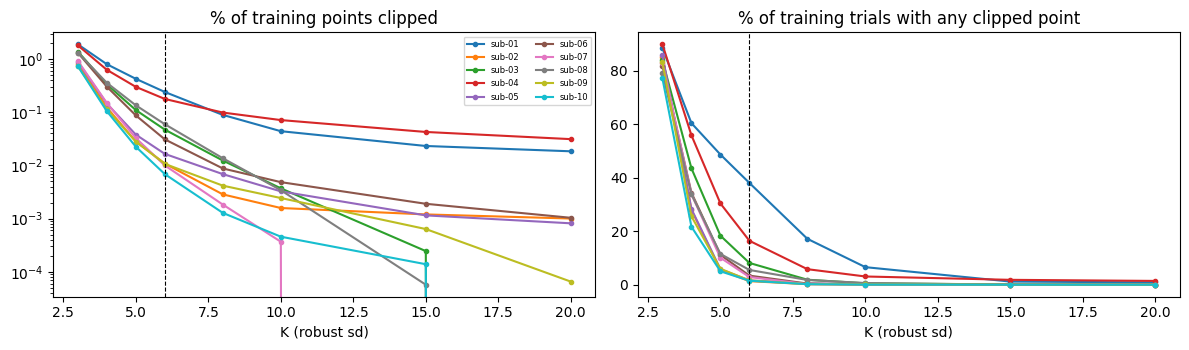

In [7]:
pf = pd.DataFrame({s: CLIPFRAC[s][0] for s in SUBJECTS}); tf = pd.DataFrame({s: CLIPFRAC[s][1] for s in SUBJECTS})
print('share of training POINTS beyond +-K robust sd (rows = K):'); display((100 * pf).round(3))
print('share of training TRIALS with any point beyond +-K (%):'); display((100 * tf).round(2))
K_REC = next((K for K in K_GRID if pf.loc[K].mean() <= CLIP_RULE), K_GRID[-1])
CLIP_K = float(CLIP_K_OVERRIDE) if CLIP_K_OVERRIDE else float(K_REC)
print(f'recommended K (rule: mean clipped points <= {CLIP_RULE:.1%}) = {K_REC} | using CLIP_K = {CLIP_K}')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for s in SUBJECTS: ax[0].plot(K_GRID, 100 * pf[s], marker='o', ms=3, label=s); ax[1].plot(K_GRID, 100 * tf[s], marker='o', ms=3)
ax[0].set_yscale('log'); ax[0].set_title('% of training points clipped'); ax[1].set_title('% of training trials with any clipped point')
for a in ax: a.axvline(CLIP_K, c='k', ls='--', lw=.8); a.set_xlabel('K (robust sd)')
ax[0].legend(ncol=2, fontsize=6); savefig('clip_threshold.png')

**Conclusion, section 3 [TRAIN]**
- *What it showed:* the robust scale (median-based sd) is about 0.62-0.84 per subject (single channels 0.24-1.07) and the median is close to 0 (about -0.07 to 0). Chosen clip threshold: **K = 6 robust sd** (smallest K that clips at most 0.1% of training points on average).
- At K = 6 only 0.007% (sub-10) to 0.24% (sub-01) of points are clipped, but the share of *trials* with at least one clipped point differs a lot: **sub-01 38%, sub-04 16%**, sub-03 8%, the rest 1-6%. Sub-01 and sub-04 are the "dirty" subjects (consistent with the extreme values seen in the EDA).
- *Why we need it:* the clip threshold is a design parameter and now rests on training data only. Robust statistics keep the huge outliers (down to about -330) from distorting the scale.

## 4. Within-subject: do the statistics transfer to validation concepts? [TRAIN]
For within-subject experiments the statistics of subject *s* come from its own training concepts. A quick check that validation-concept trials look the same after scaling: the median of |z| should be about 0.67 for a Gaussian, and the clipped share should match training.

In [8]:
rows = []
for s in SUBJECTS:
    zv = (VAL_RAW[s] - STATS[s]['median'][:, None]) / STATS[s]['scale'][:, None]
    zt = (TRAIN_SUB[s][..., CROP] - STATS[s]['median'][:, None]) / STATS[s]['scale'][:, None]
    rows.append(dict(subject=s, median_abs_z_train=np.median(np.abs(zt)), median_abs_z_val=np.median(np.abs(zv)),
                     pct_clipped_train=100 * (np.abs(zt) > CLIP_K).mean(), pct_clipped_val=100 * (np.abs(zv) > CLIP_K).mean()))
    del zv, zt
display(pd.DataFrame(rows).set_index('subject').round(3))

,median_abs_z_train,median_abs_z_val,pct_clipped_train,pct_clipped_val
subject,,,,
sub-01,0.674,0.679,0.233,0.250
sub-02,0.674,0.677,0.013,0.012
sub-03,0.675,0.677,0.046,0.045
sub-04,0.676,0.672,0.182,0.181
sub-05,0.673,0.678,0.016,0.024
sub-06,0.673,0.673,0.024,0.032
sub-07,0.673,0.677,0.009,0.007
sub-08,0.677,0.682,0.066,0.075
sub-09,0.676,0.676,0.014,0.010


**Conclusion, section 4 [TRAIN]**
- *What it showed:* after scaling with the training-concept statistics, the median of |z| is 0.672-0.682 on validation concepts versus 0.673-0.677 on training concepts (0.674 is the value expected for a Gaussian), and the clipped share is the same (validation 0.005-0.25%, training 0.008-0.23%).
- *Why we need it:* confirms the statistics fitted on training concepts transfer to held-out concepts, so for within-subject runs we can use each subject's own statistics without further checks.

## 5. LOSO: how to normalise the new subject? [TRAIN, PROXY]
The caveat discussed before: for a subject never seen in training, we need statistics (median, scale). Two options:
- **A (own statistics):** the new subject's own *unlabelled* training EEG, no labels, no test data. Assumes a short calibration recording of the new person is available.
- **B (pooled statistics):** average of the statistics of the training subjects. Nothing from the new subject is used.
- **C (reference):** no scaling at all (raw values).

Proxy check: for each fold and each of its 2 **validation subjects** *v*, take *v*'s trial-averaged responses to validation-concept images and identify the image among 165 (one random image per validation concept, 20 draws) using the average response of the training subjects as the gallery (training subjects always use their own statistics). Higher is better. This uses validation subjects x validation concepts only and no test subject or test image.

This is only a quick alignment check with a plain correlation. The final decision A vs B must come from the validation score of the trained model.

,fold,val_subject,top1_A_own,top5_A_own,top1_B_pooled,top5_B_pooled,top1_C_raw,top5_C_raw
0,sub-01,sub-02,3.3,11.8,2.8,11.3,3.0,12.0
1,sub-01,sub-03,4.3,15.5,4.5,15.8,4.5,15.9
2,sub-02,sub-03,3.2,13.5,3.3,13.9,3.5,14.5
3,sub-02,sub-04,3.8,11.9,3.8,12.4,4.0,12.9
4,sub-03,sub-04,3.6,12.3,3.7,12.6,4.0,13.5
5,sub-03,sub-05,2.6,10.4,2.5,9.5,2.6,10.6
6,sub-04,sub-05,3.7,11.8,3.6,10.8,3.7,11.9
7,sub-04,sub-06,2.8,10.7,2.5,10.0,2.7,10.8
8,sub-05,sub-06,2.5,9.9,2.5,9.8,2.6,10.2
9,sub-05,sub-07,4.1,13.8,4.2,14.9,4.2,15.3


,mean,sd
top1_A_own,3.74,0.95
top1_B_pooled,3.76,1.05
top1_C_raw,3.90,1.09


A minus B: mean -0.02 points, A better in 9 of 20 evaluations (chance level = 0.61%)


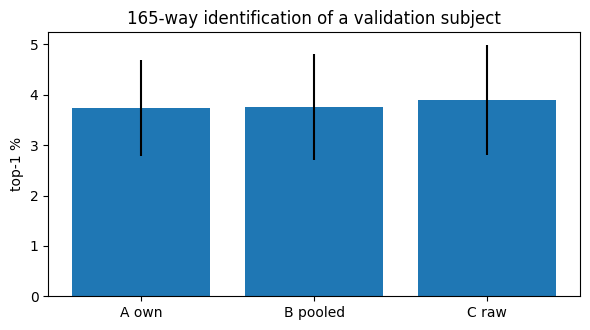

In [9]:
def pooled(train_subjects):
    return dict(median=np.mean([STATS[t]['median'] for t in train_subjects], 0),
                scale=np.mean([STATS[t]['scale'] for t in train_subjects], 0))

assert IS_VAL.sum() == n_val * 10
base = np.arange(n_val) * 10                         # validation rows are contiguous groups of 10 per concept
PRE_OWN = {s: preprocess(VAL_RAW[s], STATS[s], CLIP_K, crop=False).mean(1) for s in SUBJECTS}    # (825..1650, 17, 60)
rng = np.random.default_rng(SEED + 2); rows = []
for test_s, F in FOLDS.items():
    P = pooled(F['train']); G = np.mean([PRE_OWN[t] for t in F['train']], 0)
    for v in F['val']:
        Q = {'A_own': PRE_OWN[v], 'B_pooled': preprocess(VAL_RAW[v], P, CLIP_K, crop=False).mean(1), 'C_raw': VAL_RAW[v].mean(1)}
        r = {k: [] for k in Q}
        for _ in range(N_DRAWS):
            idx = base + rng.integers(0, 10, n_val)
            for k in Q: r[k].append(ident_arr(Q[k][idx], G[idx]))
        row = dict(fold=test_s, val_subject=v)
        for k in Q: row[f'top1_{k}'] = 100 * np.mean([x[0] for x in r[k]]); row[f'top5_{k}'] = 100 * np.mean([x[1] for x in r[k]])
        rows.append(row)
LOSO_NORM = pd.DataFrame(rows)
display(LOSO_NORM.round(1))
cols = ['top1_A_own', 'top1_B_pooled', 'top1_C_raw']
summ = pd.DataFrame({'mean': LOSO_NORM[cols].mean(), 'sd': LOSO_NORM[cols].std()}).round(2)
display(summ)
d = LOSO_NORM['top1_A_own'] - LOSO_NORM['top1_B_pooled']
print(f'A minus B: mean {d.mean():.2f} points, A better in {(d > 0).sum()} of {len(d)} evaluations (chance level = {100 / n_val:.2f}%)')
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(['A own', 'B pooled', 'C raw'], summ['mean'], yerr=summ['sd']); ax.set_ylabel('top-1 %'); ax.set_title(f'{n_val}-way identification of a validation subject'); savefig('loso_normalisation.png')

**Conclusion, section 5 [TRAIN, PROXY]**
- *What it showed:* top-1 identification of a validation subject among 165 images (chance 0.61%): **A own statistics 3.74% (sd 0.95), B pooled 3.76% (sd 1.05), C raw 3.90% (sd 1.09)**. A is better than B in 9 of 20 evaluations, mean difference -0.02 points. The three variants are indistinguishable; even the raw data is not worse.
- *Limit of this check:* the score is a plain correlation of whole response vectors, which is only weakly sensitive to per-channel scaling, so it cannot separate the options.
- *Decision:* use **B (pooled statistics of the training subjects) as the main LOSO setting**, because nothing from the new subject is used and there is no evidence that A helps. Keep A as an optional ablation to be compared with the trained model on validation.

## 6. Time window on training data [TRAIN]
Earlier the window analysis used the test EEG (hypothesis only). Here the same sweep uses **training trials only**: repetitions (0,1) against (2,3), 200 random images, preprocessed with the subject's own statistics, mean over subjects. With only 2 vs 2 repetitions absolute numbers are low; look at the *trend*.

In [10]:
starts = [0, 50, 100, 200]; ends = [300, 400, 500, 600, 790]
def sym(A, B):
    a, b = ident_arr(A, B), ident_arr(B, A); return 100 * (a[0] + b[0]) / 2
rng = np.random.default_rng(SEED + 3); W = np.zeros((len(SUBJECTS), len(starts), len(ends)))
for si, s in enumerate(SUBJECTS):
    Z = preprocess(TRAIN_SUB[s], STATS[s], CLIP_K, crop=False)                  # full time axis, (1500, 4, 17, 100)
    A, B = Z[:, 0:2].mean(1), Z[:, 2:4].mean(1)
    for ai, a in enumerate(starts):
        for ei, e in enumerate(ends):
            m = (TS >= a / 1000 - 1e-9) & (TS <= e / 1000 + 1e-9)
            W[si, ai, ei] = np.mean([sym(A[ix][:, :, m], B[ix][:, :, m]) for ix in (rng.choice(len(A), 200, replace=False) for _ in range(3))])
    del Z, A, B
wtab = pd.DataFrame(W.mean(0), index=[f'start {a} ms' for a in starts], columns=[f'end {e} ms' for e in ends])
display(wtab.round(1)); print('best cell:', np.unravel_index(W.mean(0).argmax(), W.shape[1:]), '| top-1 %, chance 0.5')

,end 300 ms,end 400 ms,end 500 ms,end 600 ms,end 790 ms
start 0 ms,3.1,3.0,2.4,2.2,1.6
start 50 ms,3.6,3.2,3.2,2.5,1.8
start 100 ms,3.9,3.4,2.8,2.4,1.7
start 200 ms,2.2,2.3,2.0,1.7,1.2


best cell: (np.int64(2), np.int64(0)) | top-1 %, chance 0.5


**Conclusion, section 6 [TRAIN]**
- *What it showed:* the best cell is start 100 ms / end 300 ms (3.9% top-1, chance 0.5%), followed by 50-300 ms (3.6%) and 0-300 ms (3.1%). Longer windows are worse (ending at 790 ms: 1.6-1.8%); starting at 200 ms loses a lot (2.2% for 200-300 ms).
- This agrees with the earlier test-based hypothesis (start about 50 ms, end 300-400 ms) and with the NICE paper (information starts around 100 ms), so the finding no longer rests on test data alone.
- *Caution:* this score weights all time points equally, so it favours short windows; a network can learn to ignore noisy late samples. The window is therefore **not final**: start with 0-590 ms (wide and safe) and compare it with 50-400 ms (or 100-400 ms) on the validation score of the trained model.

## 7. 17 vs 63 channels on training data [TRAIN, PROXY]
Which channel set carries the most image information? Same idea as the window sweep: repetitions (0,1) against (2,3) of **training images from training concepts**, robust per-channel scaling fitted on training data, 200-way identification, 3 random draws per subject (the same draws for every channel set, so sets are compared on identical images). Needs the 63-channel files (3.4 GB per subject in RAM, so use Colab High-RAM). `stim` is dropped. Set `EDA_CHAN_CMP=0` to skip.

Channel sets: occipital (O*, PO*), the 17 posterior channels, 17 + TP7/8/9/10, all 63 minus the "frontal/rest" group, all 63, and temporal / frontal alone for reference.

**Limits:** this score gives every channel the same weight, so extra noisy channels *hurt* it, whereas a trained network can learn to down-weight them. Also only 2 vs 2 repetitions are used. So this is a sanity check, **not** the final answer: the decision 17 vs 63 comes from the validation score of the trained model (compare the same sets there).

eeg/63ch/sub-01/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B / 3.39GB            

eeg/63ch/sub-01/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

{'occipital': 8, '17ch': 17, '17ch+TP7/8/9/10': 21, '63 minus frontal': 48, 'all 63': 63, 'temporal': 10, 'frontal(rest)': 15}
[   139s] sub-01 {'17ch': 2.6, '63 minus frontal': 1.3, 'all 63': 1.6}


eeg/63ch/sub-02/preprocessed_eeg_trainin(…): reconstructing file:   0%|          |  0.00B / 3.39GB            

eeg/63ch/sub-02/preprocessed_eeg_trainin(…): downloading bytes:           |  0.00B            

[   156s] sub-02 {'17ch': 1.2, '63 minus frontal': 0.9, 'all 63': 1.8}


... (23 outputs left out)

[   281s] sub-10 {'17ch': 4.4, '63 minus frontal': 1.4, 'all 63': 0.9}


,occipital,17ch,17ch+TP7/8/9/10,63 minus frontal,all 63,temporal,frontal(rest)
sub-01,3.6,2.6,2.7,1.3,1.6,0.9,0.6
sub-02,1.8,1.2,1.2,0.9,1.8,0.8,1.9
sub-03,4.3,3.4,3.4,1.8,1.4,0.5,1.0
sub-04,3.5,2.3,2.0,1.4,1.2,1.1,0.6
sub-05,2.8,1.1,1.5,0.8,1.2,0.2,0.4
sub-06,3.7,2.3,2.2,1.2,1.2,0.5,1.1
sub-07,5.5,3.6,3.1,1.5,0.8,0.3,0.2
sub-08,6.2,5.4,4.5,2.0,2.2,0.3,0.4
sub-09,2.8,1.5,1.2,1.3,2.0,0.5,0.6
sub-10,6.3,4.4,4.0,1.4,0.9,1.2,0.1


,mean top-1 %,sd
temporal,0.63,0.33
frontal(rest),0.68,0.54
63 minus frontal,1.37,0.35
all 63,1.42,0.47
17ch+TP7/8/9/10,2.58,1.15
17ch,2.79,1.41
occipital,4.05,1.54


63 minus frontal vs 17ch: mean difference -1.43 points, 63-minus-frontal better in 0 of 10 subjects


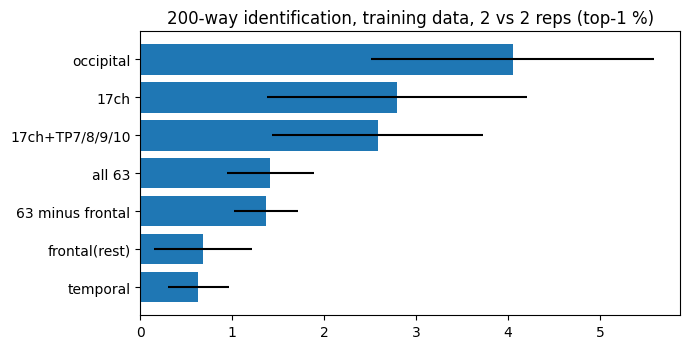

In [11]:
RUN_CHANNEL_COMPARISON = os.environ.get('EDA_CHAN_CMP', '1') == '1'
import re
CHAN_RES = {}; SETS = None
if RUN_CHANNEL_COMPARISON:
    rng = np.random.default_rng(SEED + 4); train_rows = np.flatnonzero(~IS_VAL)
    for s in SUBJECTS:
        p = get_file(f'eeg/63ch/{s}/preprocessed_eeg_training.npy'); T = safe_load(p); release(p)
        nm = T['ch_names']; assert nm[-1] == 'stim' and len(nm) == 64, nm[-3:]
        if SETS is None:
            nm63 = nm[:63]; ix = {n: i for i, n in enumerate(nm63)}
            def pick(rx): return [ix[n] for n in nm63 if re.match(rx, n)]
            Gp = {'occipital': pick(r'^(O|PO)'), 'parietal': pick(r'^P[0-9z]'), 'temporal': pick(r'^(T|TP|FT)'), 'central': pick(r'^(C|CP|FC)')}
            used = set(sum(Gp.values(), [])); frontal = [ix[n] for n in nm63 if ix[n] not in used]
            c17 = [ix[c] for c in CH17]
            SETS = {'occipital': Gp['occipital'], '17ch': c17, '17ch+TP7/8/9/10': c17 + [ix[c] for c in ['TP7', 'TP8', 'TP9', 'TP10'] if c in ix],
                    '63 minus frontal': [i for i in range(63) if i not in frontal], 'all 63': list(range(63)),
                    'temporal': Gp['temporal'], 'frontal(rest)': frontal}
            print({k: len(v) for k, v in SETS.items()})
        samp = rng.choice(train_rows, N_STAT_IMAGES, replace=False)
        Ys = T['preprocessed_eeg_data'][samp][:, :, :63].astype(np.float32)        # drop stim
        del T; gc.collect()
        st = dict(zip(('median', 'scale'), fit_stats(Ys)))
        Z = preprocess(Ys[:N_TRAIN_SUB], st, CLIP_K); del Ys                        # (1500, 4, 63, 60)
        A, B = Z[:, 0:2].mean(1), Z[:, 2:4].mean(1); del Z
        draws = [rng.choice(N_TRAIN_SUB, 200, replace=False) for _ in range(3)]
        CHAN_RES[s] = {k: float(np.mean([sym(A[d][:, ch], B[d][:, ch]) for d in draws])) for k, ch in SETS.items()}
        del A, B; gc.collect()
        log(s, {k: round(v, 1) for k, v in CHAN_RES[s].items() if k in ('17ch', '63 minus frontal', 'all 63')})
    CHAN_TAB = pd.DataFrame(CHAN_RES).T
    m = CHAN_TAB.mean().sort_values(); sd = CHAN_TAB.std()[m.index]
    display(CHAN_TAB.round(1)); display(pd.DataFrame({'mean top-1 %': m, 'sd': sd}).round(2))
    d = CHAN_TAB['63 minus frontal'] - CHAN_TAB['17ch']
    print(f'63 minus frontal vs 17ch: mean difference {d.mean():.2f} points, 63-minus-frontal better in {(d > 0).sum()} of {len(d)} subjects')
    fig, ax = plt.subplots(figsize=(7, 3.6)); ax.barh(m.index, m.values, xerr=sd.values)
    ax.set_title('200-way identification, training data, 2 vs 2 reps (top-1 %)'); savefig('channel_sets_train.png')
else:
    print('EDA_CHAN_CMP=0 -> skipped')

**Conclusion, section 7 [TRAIN, PROXY]**
- *What it showed* (mean top-1, 200-way, 2 vs 2 repetitions, chance 0.5%): occipital 4.05%, **17 posterior 2.79%**, 17 + TP 2.58%, all 63 1.42%, 63 minus frontal 1.37%, frontal 0.68%, temporal 0.63%. The 8 occipital channels beat the 17 in **all 10 subjects**, and "63 minus frontal" never beats the 17 channels (0 of 10).
- This confirms on **training data** that the information sits in occipital/parietal channels and that frontal channels carry almost none, so dropping frontal channels and `stim` is safe.
- *Limit:* every channel gets the same weight here, so extra noisy channels lower the score, and temporal channels look like noise with only 2 repetitions although NICE reports that removing them costs accuracy (-1.9%). It does **not** prove that 17 beats 63 for a trained model.
- *Decision:* start with the **17 posterior channels**. In the model comparison also try occipital-only (8) and 63 minus frontal, and choose by validation score.

## 8. Apply to the test EEG (transform only)
The test EEG is processed with the **same function and the same training statistics**. Nothing is fitted on it and no metric is computed here; the table only checks shapes and NaNs. Repetitions are averaged over all 80 (as in NICE); training images have 4 repetitions, so test inputs are cleaner.

In [12]:
def preprocess_test(s, stats=None):
    X = load_eeg(s, 'test'); assert X.shape == (200, 80, 17, 100), X.shape
    return preprocess(X, STATS[s] if stats is None else stats, CLIP_K).mean(1)         # (200, 17, 60)

rows = []
for s in SUBJECTS:
    T = preprocess_test(s)
    rows.append(dict(subject=s, shape=str(T.shape), nan=int(np.isnan(T).sum()), abs_max=float(np.abs(T).max())))
    del T; gc.collect()
display(pd.DataFrame(rows).set_index('subject'))

eeg/17ch/sub-02/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  218MB            

eeg/17ch/sub-02/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

eeg/17ch/sub-03/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  218MB            

eeg/17ch/sub-03/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

eeg/17ch/sub-04/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  218MB            

eeg/17ch/sub-04/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

... (9 outputs left out)

eeg/17ch/sub-09/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

eeg/17ch/sub-10/preprocessed_eeg_test.np(…): reconstructing file:   0%|          |  0.00B /  218MB            

eeg/17ch/sub-10/preprocessed_eeg_test.np(…): downloading bytes:           |  0.00B            

,shape,nan,abs_max
subject,,,
sub-01,"(200, 17, 60)",0,2.717321
sub-02,"(200, 17, 60)",0,2.141579
sub-03,"(200, 17, 60)",0,2.856812
sub-04,"(200, 17, 60)",0,2.307404
sub-05,"(200, 17, 60)",0,2.267041
sub-06,"(200, 17, 60)",0,2.845616
sub-07,"(200, 17, 60)",0,2.883079
sub-08,"(200, 17, 60)",0,2.896590
sub-09,"(200, 17, 60)",0,1.579288


**Conclusion, section 8**
- *What it showed:* the test EEG of every subject becomes an array of shape (200, 17, 60) with no NaN and values within about +-2.9 after averaging 80 repetitions, using the same function and the training statistics of that subject. No test metric was computed.
- *Why we need it:* the test input is built exactly like the training input and nothing was fitted on test data. Note that test images are averaged over 80 repetitions and training images over 4, so test inputs are cleaner; mention this in the report.

## 9. Save the artifacts
`split_concepts.json` (validation concepts + LOSO folds) and `preproc_stats.json` (per-subject own statistics, pooled statistics per fold, `CLIP_K`, window, channels). Share these two files with the team so that everyone uses the identical split and preprocessing.

**How to use in the training code**

In [15]:
cfg = json.load(open(os.path.join(OUT, 'preproc_stats.json')))
split = json.load(open(os.path.join(OUT, 'split_concepts.json')))
print(cfg['clip_k'], cfg['crop_ms'], len(cfg['own']), len(split['validation_concepts']))

6.0 [0, 590] 10 165


In [13]:
def lst(a): return [float(v) for v in a]
cfg = dict(source=SOURCE, channels=CH17, crop_ms=list(CROP_MS), n_time_points=int(CROP.sum()), clip_k=CLIP_K, clip_rule=CLIP_RULE,
           own={s: dict(median=lst(STATS[s]['median']), scale=lst(STATS[s]['scale'])) for s in SUBJECTS},
           loso={s: dict(val=F['val'], train=F['train'], pooled={k: lst(v) for k, v in pooled(F['train']).items()}) for s, F in FOLDS.items()},
           note='robust stats: median and 1.4826*MAD per channel, fitted on training images of TRAINING concepts only')
with open(os.path.join(OUT, 'preproc_stats.json'), 'w') as f: json.dump(cfg, f, indent=1)
LOSO_NORM.to_csv(os.path.join(OUT, 'loso_normalisation.csv'), index=False); wtab.to_csv(os.path.join(OUT, 'window_sweep_train.csv'))
if CHAN_RES: CHAN_TAB.to_csv(os.path.join(OUT, 'channel_sets_train.csv'))
print(os.listdir(OUT))
zp = shutil.make_archive(os.path.join(WORK, 'preproc_out'), 'zip', OUT)
try:
    from google.colab import files; files.download(zp)
except Exception:
    print('saved', zp)

['loso_normalisation.png', 'channel_sets_train.png', 'window_sweep_train.csv', 'clip_threshold.png', 'preproc_stats.json', 'channel_sets_train.csv', 'loso_normalisation.csv', 'split_concepts.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What is decided and what is still open
| Decision | Status | Evidence |
|---|---|---|
| Validation: 165 fixed concepts (10%), seed 0, shared by all subjects and models | decided | EDA section 5 [TRAIN], section 1 |
| LOSO: 1 test, 2 validation, 7 training subjects; training subjects use training concepts only | decided | design |
| Per-subject robust normalisation (median, 1.4826 x MAD), fitted on training concepts only | decided | sections 3-4 [TRAIN] |
| Shared clip threshold K = 6 robust sd | decided (re-check if the channel set changes) | section 3 [TRAIN] |
| LOSO normalisation of the new subject | default **B pooled**; A as ablation | section 5: no difference found |
| Drop `stim` and frontal channels | decided | EDA [TRAIN], section 7 |
| Channel set | **open**: start with 17, compare occipital-8 and 63 minus frontal | section 7 [PROXY], NICE ablation |
| Time window | **open**: start 0-590 ms, compare 50-400 / 100-400 ms | section 6 [TRAIN], NICE |
| Average repetitions (4 per training image, 80 for test) | decided | NICE, EDA |
| Test set | touched only for the final evaluation | proposal |